### 0D solver class

In [74]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [75]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

In [76]:
import RE as RE
import importlib
importlib.reload(RE)

solver = RE.solver0D()
solver.display() # Show default values


Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


In [56]:
solver.n_imp = 1e20
solver.k = 1.70
solver.Ir0 = 1e4
solver.iDreicer = 1
solver.tmax = 3e-3
solver.display()

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.700
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1e+04
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e+20
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


10000
10000
[8700000.         8699999.80396657 8699999.60698472 ... 2912844.68778955
 2912437.79889281 2912030.96670476]


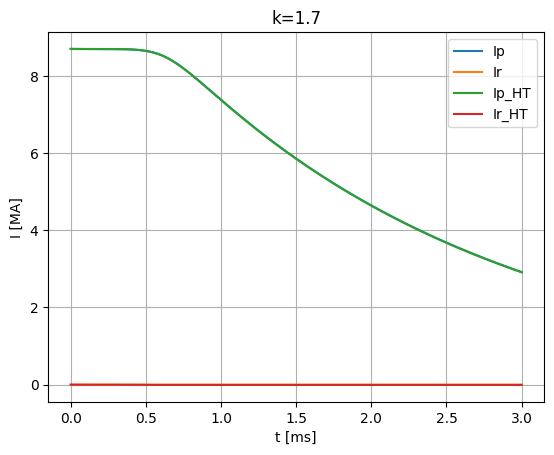

In [82]:
# solve
solver.n_imp = 1e20
solver.k = 1.70
solver.Ir0 = 0
solver.iDreicer = 0
solver.tmax = 3e-3
solver.iHotTail = 0
t, Ip, Ir, Wk = solver.solve()

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title(f'k={solver.k}')

solver.n_imp = 1e20
solver.k = 1.70
solver.Ir0 = 0
#solver.iDreicer = 0
solver.tmax = 3e-3
solver.iHotTail = 1
solver.iAvalanche = 0

t2, Ip2, Ir2, Wk2 = solver.solve()
print(len(t2))
print(len(Ip2))
print(Ip2)

plt.plot(t2*1e3,Ip2/1e6,label='Ip_HT')
plt.plot(t2*1e3,Ir2/1e6,label='Ir_HT')
plt.legend()

[    0.             0.             0.         ... -6552.06537861
 -6552.06537861 -6552.06537861]


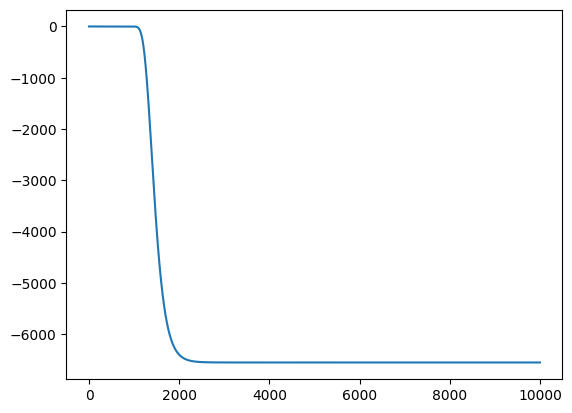

In [84]:
print(Ir2)
plt.plot(Ir2)

Text(0, 0.5, 'I [MA]')

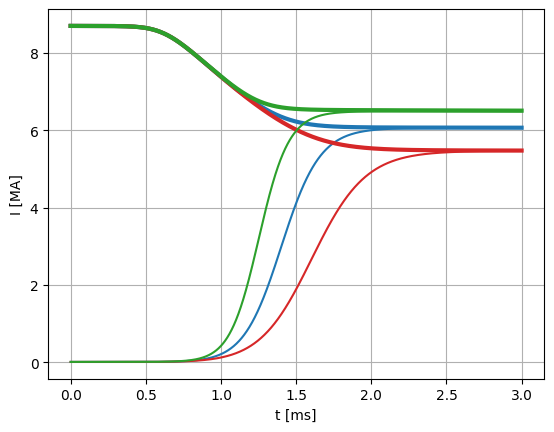

In [95]:
# Change settings and solve again

solver.iAvalanche = 1
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:blue',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:blue')

solver.iAvalanche = 2
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:red',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:red')

solver.iAvalanche = 3
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:green',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:green')



plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')

In [36]:
for i in range(0, len(t), 100):
    print(f'time: {t[i]*1e3}, Ir Current: {Ir[i]/1e6}')

time: 0.0, Ir Current: 0.01
time: 0.030003000300030003, Ir Current: 0.01
time: 0.060006000600060005, Ir Current: 0.01
time: 0.09000900090009001, Ir Current: 0.01
time: 0.12001200120012001, Ir Current: 0.01
time: 0.15001500150015, Ir Current: 0.010000626990659713
time: 0.18001800180018002, Ir Current: 0.010003256136089114
time: 0.21002100210021002, Ir Current: 0.010006652984537045
time: 0.24002400240024002, Ir Current: 0.010010975908242941
time: 0.27002700270027, Ir Current: 0.010018114452515006
time: 0.3000300030003, Ir Current: 0.010031689335730221
time: 0.33003300330033003, Ir Current: 0.010057052449334337
time: 0.36003600360036003, Ir Current: 0.010101286857841884
time: 0.39003900390039004, Ir Current: 0.010173206798836156
time: 0.42004200420042004, Ir Current: 0.010283357700276243
time: 0.4500450045004501, Ir Current: 0.010454399330232894
time: 0.48004800480048004, Ir Current: 0.01071340902084642
time: 0.51005100510051, Ir Current: 0.011103015486260706
time: 0.54005400540054, Ir Cu

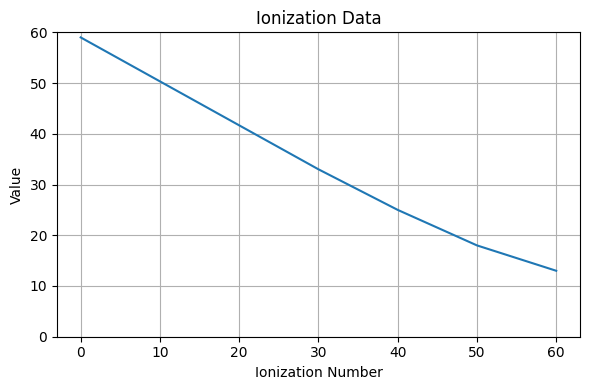

In [ ]:
ionization = [0, 30, 40, 50, 60]
a_j = [59, 33, 25, 18, 13]
plt.figure(figsize=(6, 4))
plt.plot(x, y)
plt.xlabel('Ionization Number')
plt.ylabel('Value')
plt.ylim((0,60))
plt.title('Ionization Data')
plt.grid(True)
plt.tight_layout()
plt.show()


In [67]:
def interpolate_aBar_W(Zion):
    Z_tab = np.array([0, 30, 40, 50, 60])
    aBar_tab = np.array([59, 33, 25, 18, 13])

    
    if Zion <= Z_tab[0]:
        return aBar_tab[0]
    if Zion >= Z_tab[-1]:
        return aBar_tab[-1]

    
    i = np.searchsorted(Z_tab, Zion) - 1

    Zlow, Zhigh = Z_tab[i], Z_tab[i+1]
    aLow, aHigh = aBar_tab[i], aBar_tab[i+1]


    w = (Zion - Zlow) / (Zhigh - Zlow)

    return (1 - w) * aLow + w * aHigh

Z_list = np.arange(61)  # 0, 1, ..., 60
aBar_list = np.array([interpolate_aBar_W(Z) for Z in Z_list])
ln_aBar_list = np.log(aBar_list)
print(ln_aBar_list)

[4.07753744 4.06273922 4.04771872 4.03246916 4.01698344 4.00125414
 3.98527347 3.96903326 3.95252495 3.93573953 3.91866755 3.90129904
 3.88362353 3.86562997 3.84730669 3.8286414  3.80962107 3.79023195
 3.77045944 3.75028808 3.72970145 3.70868208 3.6872114  3.66526959
 3.64283552 3.61988658 3.5963986  3.57234564 3.54769984 3.52243125
 3.49650756 3.47196645 3.44680789 3.42100001 3.39450839 3.36729583
 3.33932198 3.31054301 3.28091122 3.25037449 3.21887582 3.19047635
 3.16124671 3.13113691 3.10009229 3.06805294 3.03495299 3.00071982
 2.96527307 2.92852352 2.89037176 2.86220088 2.83321334 2.80336038
 2.77258872 2.74084002 2.7080502  2.67414865 2.63905733 2.60268969
 2.56494936]


In [69]:
def aBar_W(Zion):
    Z_tab = np.array([0, 30, 40, 50, 60])
    a_tab = np.array([59, 33, 25, 18, 13])
    if Zion <= Z_tab[0]:
        return a_tab[0]

    # Above highest: linear extrapolation
    if Zion > Z_tab[-1]:
        log_slope = (np.log(a_tab[-1]) - np.log(a_tab[-2])) / (Z_tab[-1] - Z_tab[-2])
        return np.exp(np.log(a_tab[-1]) + log_slope * (Zion - Z_tab[-1]))


    # Interpolation
    i = np.searchsorted(Z_tab, Zion) - 1
    Zl, Zh = Z_tab[i], Z_tab[i+1]
    al, ah = a_tab[i], a_tab[i+1]

    w = (Zion - Zl) / (Zh - Zl)
    return (1 - w) * al + w * ah


Z_list = np.arange(75)  # 0 … 74
aBar_list = np.array([aBar_W(Z) for Z in Z_list])
ln_aBar_list = np.log(aBar_list)
print(ln_aBar_list)

[4.07753744 4.06273922 4.04771872 4.03246916 4.01698344 4.00125414
 3.98527347 3.96903326 3.95252495 3.93573953 3.91866755 3.90129904
 3.88362353 3.86562997 3.84730669 3.8286414  3.80962107 3.79023195
 3.77045944 3.75028808 3.72970145 3.70868208 3.6872114  3.66526959
 3.64283552 3.61988658 3.5963986  3.57234564 3.54769984 3.52243125
 3.49650756 3.47196645 3.44680789 3.42100001 3.39450839 3.36729583
 3.33932198 3.31054301 3.28091122 3.25037449 3.21887582 3.19047635
 3.16124671 3.13113691 3.10009229 3.06805294 3.03495299 3.00071982
 2.96527307 2.92852352 2.89037176 2.86220088 2.83321334 2.80336038
 2.77258872 2.74084002 2.7080502  2.67414865 2.63905733 2.60268969
 2.56494936 2.53240712 2.49986488 2.46732264 2.4347804  2.40223816
 2.36969592 2.33715368 2.30461144 2.2720692  2.23952696 2.20698472
 2.17444248 2.14190024 2.109358  ]


In [ ]:
len([751, 775, 801, 827, 855, 885, 917, 950, 985, 1020, 1060, 1110, 1150, 1200, 1250, 1310, 1370, 1430, 1500, 1580, 1660, 1720, 1780, 1840, 1900,
                                 1970, 2050, 2130, 2210, 2300, 2400, 2500, 2610, 2730, 2850, 2990, 3140, 3300, 3470, 3660, 3870, 4100, 4350, 4630, 4940, 5290, 5680, 5960, 6270,
                                 6610, 6980, 7380, 7830, 8310, 8860, 9460, 1.01e4, 1.09e4, 1.17e4, 1.27e4, 1.38e4, 1.51e4, 1.66e4, 1.83e4, 2.04e4, 2.08e4, 2.14e4, 2.22e4,
                                 2.33e4, 2.50e4, 2.84e4, 3.64e4, 8.79e4, 8.91e4])


74

In [71]:
len([4.07753744, 4.06273922, 4.04771872, 4.03246916, 4.01698344, 4.00125414, 3.98527347, 3.96903326, 3.95252495, 3.93573953, 3.91866755, 3.90129904,
                            3.88362353, 3.86562997, 3.84730669, 3.8286414, 3.80962107, 3.79023195, 3.77045944, 3.75028808, 3.72970145, 3.70868208, 3.6872114, 3.66526959,
                            3.64283552, 3.61988658, 3.5963986, 3.57234564, 3.54769984, 3.52243125, 3.49650756, 3.47196645, 3.44680789, 3.42100001, 3.39450839, 3.36729583,
                            3.33932198, 3.31054301, 3.28091122, 3.25037449, 3.21887582, 3.19047635, 3.16124671, 3.13113691, 3.10009229, 3.06805294, 3.03495299, 3.00071982,
                            2.96527307, 2.92852352, 2.89037176, 2.86220088, 2.83321334, 2.80336038, 2.77258872, 2.74084002, 2.7080502, 2.67414865, 2.63905733, 2.60268969,
                            2.56494936, 2.53240712, 2.49986488, 2.46732264, 2.4347804, 2.40223816, 2.36969592, 2.33715368, 2.30461144, 2.2720692, 2.23952696, 2.20698472,
                            2.17444248, 2.14190024])

74